# Kidney ultrasound CNN (TensorFlow/Keras): Normal vs Stone.
How to use: set the options in the `CFG` cell near the bottom (especially `data`), then run all cells.

Expected folder layout (what archive.zip extracts to):
    <data>/Normal/*.JPG
    <data>/stone/*.JPG

Dataset issues this script handles:
  1. ~1,000 exact-duplicate images (mostly Stone)  -> removed by hash, so the
     same picture can't land in both train and test.
  2. Colored calipers / measurement text appear ONLY on Stone images (~28% in
     a sample, 0% on Normal) -> a CNN could "cheat" by detecting the overlay.
     Colored pixels are inpainted away and images are converted to grayscale.
  3. Neighbouring file numbers are often near-identical frames -> split is
     done in contiguous blocks of file numbers, not fully at random.

In [1]:
import hashlib, re, random, json
from types import SimpleNamespace
from pathlib import Path

import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
%matplotlib inline
from tqdm import tqdm

CLASSES = {"Normal": 0, "stone": 1}
IMG = 224

## Data Preparation

In [ ]:
def clean_image(path):

    # Step 1: Read the image
    image = cv2.imread(str(path))

    # Step 2: Convert the image to HSV
    hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Step 3: Find colorful and sufficiently bright pixels
    saturation = hsv_image[:, :, 1]
    brightness = hsv_image[:, :, 2]

    colored_pixels = (saturation > 80) & (brightness > 60)

    # Step 4: Convert the mask into 0 and 255 values
    mask = colored_pixels.astype(np.uint8) * 255

    # Step 5: Expand the selected areas
    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.dilate(mask, kernel)

    # Step 6: Remove the selected areas
    if np.any(mask):
        image = cv2.inpaint(image, mask, 3, cv2.INPAINT_TELEA)

    # Step 7: Convert to grayscale
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Step 8: Resize the image
    final_image = cv2.resize(gray_image,(IMG, IMG),interpolation=cv2.INTER_AREA)

    # Step 9: Return the processed image
    return final_image


In [3]:
def num(p):
    return int(re.findall(r"(\d+)", p.stem)[-1])

In [ ]:

def build_arrays(root, cache):

    # Step 1: Convert cache path
    cache = Path(cache)

    # Step 2: Load saved data if available
    if cache.exists():
        data = np.load(cache)
        return data["x"], data["y"], data["g"]

    # Step 3: Create empty lists and a set
    images = []
    labels = []
    groups = []
    seen_images = set()
    duplicates = 0

    # Step 4: Visit each class folder
    for class_name, label in CLASSES.items():

        folder = Path(root) / class_name
        files = sorted(folder.glob("*.*"), key=num)

        # Step 5: Process each image
        for file in tqdm(files, desc=class_name):

            # Calculate the image fingerprint
            image_hash = hashlib.md5(file.read_bytes()).hexdigest()

            # Skip duplicate images
            if image_hash in seen_images:
                duplicates += 1
                continue

            seen_images.add(image_hash)

            # Clean the image and store its label
            cleaned = clean_image(file)
            images.append(cleaned)
            labels.append(label)

            # Assign a group ID
            group_id = num(file) // 20
            groups.append(group_id)

    # Step 6: Display duplicate count
    print("Removed duplicates:", duplicates)

    # Step 7: Convert lists into arrays
    x = np.stack(images)
    y = np.array(labels)
    g = np.array(groups)

    # Step 8: Save arrays in a compressed file
    np.savez_compressed(cache , x = x , y = y , g = g)

    # Step 9: Return the arrays
    return x, y, g


In [5]:
def split(y, g, seed=42):

    # Step 1: Create empty lists
    train_indices = []
    val_indices = []
    test_indices = []

    # Step 2: Create a random generator
    rng = random.Random(seed)

    # Step 3: Process each class
    for class_label in (0, 1):

        # Find groups belonging to this class
        class_groups = g[y == class_label]

        # Get unique group IDs
        blocks = sorted(set(class_groups))

        # Shuffle the groups
        rng.shuffle(blocks)

        # Count the groups
        n = len(blocks)

        # Calculate split boundaries
        train_end = int(0.70 * n)
        val_end = int(0.85 * n)

        # Select groups for each dataset
        train_groups = set(blocks[:train_end])
        val_groups = set(blocks[train_end:val_end])
        test_groups = set(blocks[val_end:])

        # Find image indices for this class
        indices = np.where(y == class_label)[0]

        # Assign images based on their group
        for i in indices:

            group_id = g[i]

            if group_id in train_groups:
                train_indices.append(i)

            elif group_id in val_groups:
                val_indices.append(i)

            else:
                test_indices.append(i)

    # Step 4: Convert lists into NumPy arrays
    train_indices = np.array(train_indices)
    val_indices = np.array(val_indices)
    test_indices = np.array(test_indices)

    # Step 5: Return the indices
    return train_indices, val_indices, test_indices


In [ ]:
def make_ds(x, y, idx, bs, train):

    # Step 1: Select images
    images = x[idx]

    # Step 2: Convert pixels to float32 and normalize
    images = images.astype("float32") / 255.0

    # Step 3: Add the grayscale channel
    images = images[..., None]

    # Step 4: Convert labels to one-hot encoding
    labels = tf.one_hot(y[idx], depth=2)

    # Step 5: Create a TensorFlow dataset
    ds = tf.data.Dataset.from_tensor_slices((images, labels))

    # Step 6: Shuffle training data
    if train:
        ds = ds.shuffle(buffer_size=len(idx) ,seed=42 ,reshuffle_each_iteration=True )

    # Step 7: Create batches
    ds = ds.batch(bs)

    # Step 8: Apply augmentation only during training
    if train:

        augmentation = tf.keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(10 / 360),
            layers.RandomZoom(0.1),
            layers.RandomBrightness(0.15, value_range=(0, 1)),
            layers.RandomContrast(0.15)
        ])

        # Modify images but keep labels unchanged
        ds = ds.map(lambda images, labels: ( augmentation(images, training=True),labels ),
        num_parallel_calls=tf.data.AUTOTUNE )

    # Step 9: Prefetch batches for faster loading
    ds = ds.prefetch(tf.data.AUTOTUNE)

    # Step 10: Return the dataset
    return ds


In [ ]:
def conv_block(x, f, reg):

    # Step 1: First convolution
    x = layers.Conv2D(
        filters=f,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_regularizer=reg)(x)

    # Step 2: Normalize the output
    x = layers.BatchNormalization()(x)

    # Step 3: Apply ReLU
    x = layers.ReLU()(x)

    # Step 4: Second convolution
    x = layers.Conv2D(
        filters=f,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_regularizer=reg)(x)

    # Step 5: Normalize the output
    x = layers.BatchNormalization()(x)

    # Step 6: Apply ReLU
    x = layers.ReLU()(x)

    # Step 7: Reduce spatial dimensions
    x = layers.MaxPooling2D(pool_size=2)(x)

    # Step 8: Return the feature maps
    return x


In [ ]:
def build_cnn(a):

    # Step 1: Configure regularization
    if a.l2:
        reg = regularizers.l2(a.l2)
    else:
        reg = None

    # Step 2: Define input image shape
    inp = layers.Input(shape=(IMG, IMG, 1))

    # Step 3: Normalize image pixels
    x = layers.Rescaling( scale=1 / 0.2 , offset=-1.0 )(inp)

    # Step 4: Crop borders if required
    if a.crop:
        x = layers.Cropping2D(a.crop)(x)

    # Step 5: Choose the number of filters
    if a.model == "small":
        filters = [16, 32, 64, 128]
    else:
        filters = [32, 64, 128, 256]

    # Step 6: Add convolution blocks
    for f in filters:
        x = conv_block(x, f, reg)

    # Step 7: Reduce feature maps to a vector
    x = layers.GlobalAveragePooling2D()(x)

    # Step 8: Apply dropout
    x = layers.Dropout(a.dropout)(x)

    # Step 9: Predict the two classes
    out = layers.Dense(2,activation="softmax", kernel_regularizer=reg )(x)

    # Step 10: Build and return the model
    model = models.Model(
        inputs=inp,
        outputs=out,
        name="KidneyCNN"
    )

    return model, None


In [ ]:
def build_transfer(a):

    # Step 1: Set up regularization
    if a.l2:
        reg = regularizers.l2(a.l2)
    else:
        reg = None

    # Step 2: Define grayscale input
    inp = layers.Input(shape=(IMG, IMG, 1))

    # Step 3: Convert grayscale to three channels
    x = layers.Concatenate()([inp, inp, inp])

    # Step 4: Crop image borders if required
    if a.crop:
        x = layers.Cropping2D(a.crop)(x)

    # Step 5: Normalize pixels from [0, 1] to [-1, 1]
    x = layers.Rescaling( scale=2.0, offset=-1.0 )(x)

    # Step 6: Select pretrained or random weights
    if a.weights == "none":
        weights = None
    else:
        weights = "imagenet"

    # Step 7: Load MobileNetV2 without its original classifier
    base = tf.keras.applications.MobileNetV2(
        include_top=False,
        input_shape=tuple(x.shape[1:]),
        weights=weights )

    # Step 8: Freeze the base network
    base.trainable = False

    # Step 9: Extract image features
    x = base(x, training=False)

    # Step 10: Convert feature maps into a vector
    x = layers.GlobalAveragePooling2D()(x)

    # Step 11: Apply dropout
    x = layers.Dropout(a.dropout)(x)

    # Step 12: Classify into two classes
    out = layers.Dense(2 ,activation="softmax" ,kernel_regularizer=reg )(x)

    # Step 13: Build the complete model
    model = models.Model(
        inputs=inp,
        outputs=out,
        name="KidneyMobileNet"
    )

    # Return classifier and feature extractor
    return model, base



In [ ]:
def compile_model(model, a, lr, steps=None):
    sched = tf.keras.optimizers.schedules.CosineDecay(lr, steps) if steps else lr

    model.compile(optimizer=tf.keras.optimizers.AdamW(sched, weight_decay=0.0001),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=a.label_smoothing),
        metrics=["accuracy"])

In [ ]:
def main(a):
    # ----------------------------CREATE RESULT DIRECTORY-----
    out = Path(a.out)
    out.mkdir(exist_ok=True)
    tf.keras.utils.set_random_seed(42)
    # -----------------------------BUILD ARRAY AND SPLIT------
    x, y, g = build_arrays(a.data, out / "cache_224.npz")
    tr, va, te = split(y, g) # Go to split() 
    print(f"train {len(tr)}  val {len(va)}  test {len(te)}  | stone share {y.mean():.2f}")
    print("GPUs:", tf.config.list_physical_devices("GPU"))
    # -----------------------------MAKE DATABASE----------
    dtr, dva, dte = (make_ds(x, y, i, a.bs, t) for i, t in ((tr, True), (va, False), (te, False)))
    model, base = build_transfer(a) if a.model == "transfer" else build_cnn(a)
    # ----------------------------COMPILE THE MODEL--------
    # transfer: constant small LR is more stable than a decay for a frozen-base phase
    compile_model(model, a, a.lr if a.model != "transfer" else min(a.lr, 0.0003), None
    if a.model == "transfer" else a.epochs * int(np.ceil(len(tr) / a.bs)))
    model.summary()
    # ---------------------------EARLY STOPPING-------------
    cbs = [callbacks.ModelCheckpoint(str(out / "best.keras"), monitor="val_accuracy",
            save_best_only=True, verbose=1),
           callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
           if a.model == "transfer" else callbacks.Callback(),
           callbacks.EarlyStopping(monitor="val_accuracy", patience=a.patience, 
            restore_best_weights=True)]
    hist = model.fit(dtr, validation_data=dva, epochs=a.epochs, callbacks=cbs, shuffle=False).history
    # -------------------------TRAINING THE MODEL-----------------
    if a.model == "transfer" and a.finetune > 0:
        base.trainable = True
        for l in base.layers[:-30]:                           # keep early layers frozen
            l.trainable = False
        compile_model(model, a, 1e-5)
        h2 = model.fit(dtr, validation_data=dva, epochs=a.finetune, callbacks=cbs, shuffle=False).history
        hist = {k: hist[k] + h2[k] for k in hist}

    # ---- --------------------OVERFITTING CHECK----------
    b = int(np.argmax(hist["val_accuracy"]))
    gap = hist["accuracy"][b] - hist["val_accuracy"][b]
    print(f"\nBest epoch {b+1}: train acc {hist['accuracy'][b]:.3f}  val acc {hist['val_accuracy'][b]:.3f}  gap {gap:+.3f}")
    print("  -> gap > ~0.05 suggests overfitting; val acc ~0.99+ with tiny gap suggests leakage, check Grad-CAM.")

    # -------------------------TESTING THE MODEL---------------
    model = tf.keras.models.load_model(out / "best.keras")
    p = model.predict(dte)[:, 1]
    t = y[te]
    pred = (p > .5).astype(int)
    print(classification_report(t, pred, target_names=["Normal", "Stone"], digits=3, zero_division=0))
    auc = roc_auc_score(t, p)
    print("AUC", auc); print(confusion_matrix(t, pred))
    json.dump({"auc": float(auc), "val_best": float(max(hist["val_accuracy"])), "train_val_gap": float(gap)},
              open(out / "metrics.json", "w"))

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(hist["loss"], label="train")
    ax[0].plot(hist["val_loss"], label="val")
    ax[0].set_title("Loss")
    ax[0].legend()
    ax[1].plot(hist["accuracy"], label="train")
    ax[1].plot(hist["val_accuracy"], label="val")
    ax[1].set_title("Accuracy")
    ax[1].legend()
    fig.savefig(out / "curves.png", dpi=120, bbox_inches="tight")
    plt.show()

In [ ]:
# ---- EDIT THESE SETTINGS ---------------------
CFG = SimpleNamespace(
    data=r"data",          # folder that directly contains the 'Normal' and 'stone' subfolders
    model="small",         # "small" | "cnn" | "transfer"
    epochs=25,
    finetune=0,            # extra epochs when model="transfer" (e.g. 10)
    bs=32,
    lr=1e-3,
    dropout=0.5,
    l2=1e-4,
    label_smoothing=0.1,
    crop=0,                # e.g. 16 to crop border text / scale bar
    weights="imagenet",    # "none" if offline
    patience=6,
    out="results",
)

train 2058  val 424  test 471  | stone share 0.03
GPUs: []


Model: "KidneyCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 16)   │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 32)   │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 56, 56, 64)     │             

 Total params: 294,930 (1.13 MB)

 Trainable params: 293,970 (1.12 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/25
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8942 - loss: 0.4725
Epoch 1: val_accuracy improved from None to 0.99528, saving model to results\best.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.9500 - loss: 0.3730 - val_accuracy: 0.9953 - val_loss: 0.3130
Epoch 2/25
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9708 - loss: 0.3102
Epoch 2: val_accuracy did not improve from 0.99528
65/65 ━━━━━━━━━━━━━━━━━━━━ 198s 3s/step - accuracy: 0.9738 - loss: 0.3043 - val_accuracy: 0.9953 - val_loss: 0.2538
Epoch 3/25
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9863 - loss: 0.2803
Epoch 3: val_accuracy did not improve from 0.99528
65/65 ━━━━━━━━━━━━━━━━━━━━ 156s 2s/step - accuracy: 0.9883 - loss: 0.2773 - val_accuracy: 0.9953 - val_loss: 0.2496
Epoch 4/25
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9939 - loss: 0.2639
Epoch 4: val_accuracy did not improve from 0.99528
65/65 ━━━━━━━━━━━━━━━━━━━━ 163s 3s/step - accuracy: 0.9903 - loss: 0.2675 - val

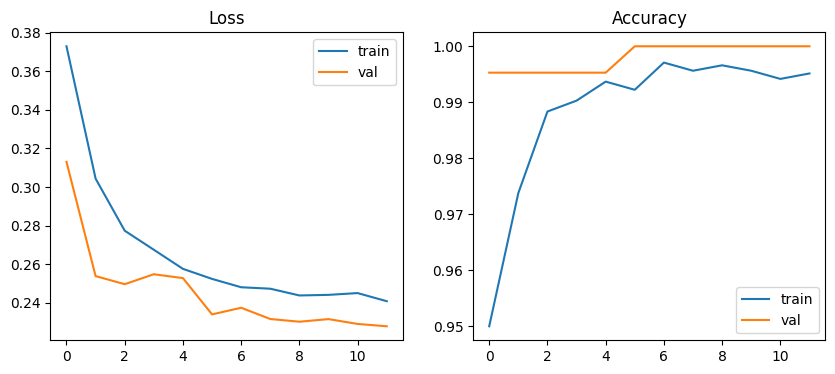

In [13]:
main(CFG)

**Here Evaluations are**

`Model accuracy 99.42% `, `loss 0.2535`

**In Confusion Matrix**

`True Positive 446`

`False Positive 0`

`True Negative 20`

`False Negative 5`

`AUC Score 0.9753363228699552`